# 03 · SQL deep-dive: the reconciliation engine in DuckDB

Day 2 found the patterns with pandas. Day 3 turns them into a **rule-based matching engine written in SQL**, so finance can read, audit and change the rules without touching Python.

The engine lives in `sql/` and runs in file order (`src/match.py`):

| File | What it does | SQL techniques |
|---|---|---|
| `00_staging.sql` | typed views over the cleaned parquet, period and tolerance parameters, contract MDR table | `REPLACE` casts, parameter table |
| `10_ledger_vs_gateway.sql` | leg 1: ERP receipts ↔ gateway payments, 9-rule cascade; probable-pair diagnostic | `FULL OUTER JOIN`, ordered `CASE` cascade, mutual-best match with `ROW_NUMBER()` |
| `20_refunds_chargebacks.sql` | refunds ↔ credit notes, chargebacks | `LEFT JOIN`, `ANTI JOIN` |
| `30_fee_audit.sql` | every capture re-priced at contract; daily effective rate | `LAG()` for step changes, running `SUM() OVER` |
| `40_settlement_vs_bank.sql` | leg 2: payouts rebuilt from transactions (many-to-one); leg 3: payout ↔ bank on UTR | `FILTER` aggregates, due-date logic, running balance window |
| `50_exception_register.sql` | one register across all legs with owner, action, age, rank and Pareto share | `UNION ALL` CTE, `RANK()`, cumulative share window |
| `60_cash_bridge.sql` | ERP net sales → bank credits, step by step | running total window, residual check |

The engine reads only `data/clean/`. It never reads `data/truth/`; scoring against the truth labels is Day 4.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from match import build, checks

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)
IMG = ROOT / "images"
INK, MUTED, ACCENT, WARN, OK, AMBER = "#1f2937", "#9ca3af", "#2563eb", "#dc2626", "#16a34a", "#f59e0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
lakh = lambda x: f"₹{x/1e5:,.2f} L"

con = build()                      # in-memory DuckDB, all sql/*.sql executed in order
sql = lambda q: con.sql(q).df()
for name, ok in checks(con):
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")

[PASS] every ERP receipt gets exactly one leg-1 outcome
[PASS] every gateway payment gets exactly one leg-1 outcome
[PASS] every refund gets exactly one outcome
[PASS] payouts rebuilt from txns tie for all complete batches
[PASS] no PayFlux bank credit without a payout
[PASS] bank running balance recomputes exactly
[PASS] cash bridge unexplained within ₹1


## 1 · Leg 1: ERP receipts ↔ gateway payments

`10_ledger_vs_gateway.sql` full-outer-joins receipts to payments on the normalised order id and assigns each key **one** outcome. The `CASE` branches are evaluated top to bottom, so the order of the rules *is* the matching policy: exact first, then the ±₹1 tolerance, then the explanations for what's left (failed attempt, cut-off window), and only then a break.

In [2]:
print(Path(ROOT / "sql" / "10_ledger_vs_gateway.sql").read_text().split("CREATE OR REPLACE TABLE rule_catalogue")[0][-1900:])

ay-only captured in October    -> break
--   R9 failed, unbooked gateway-only failed attempt         -> no action (no money moved)

CREATE OR REPLACE TABLE leg1_match AS
WITH joined AS (
    SELECT
        COALESCE(e.order_id, g.order_id)            AS order_id,
        e.voucher_no, e.posting_ts_ist, e.payment_mode, e.channel,
        e.amount_inr                                AS erp_amount,
        g.txn_id, g.status, g.method, g.ts_ist      AS gw_ts_ist, g.in_period_ist,
        g.amount_inr                                AS gw_amount,
        g.settlement_id,
        ROUND(g.amount_inr - e.amount_inr, 2)       AS diff_inr
    FROM erp_receipts e
    FULL OUTER JOIN gw_payments g USING (order_id)
)
SELECT j.*,
    CASE
        WHEN voucher_no IS NOT NULL AND status = 'captured' AND diff_inr = 0                     THEN 'R1_exact'
        WHEN voucher_no IS NOT NULL AND status = 'captured' AND ABS(diff_inr) <= p.amount_tolerance THEN 'R2_tolerance'
        WHEN voucher_no IS NOT NUL

In [3]:
leg1 = sql("""
SELECT m.rule, c.outcome, COUNT(*) AS keys, ROUND(SUM(m.value_inr), 2) AS value_inr,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_keys
FROM leg1_match m JOIN rule_catalogue c USING (rule)
GROUP BY ALL ORDER BY m.rule
""")
leg1

,rule,outcome,keys,value_inr,pct_keys
0,R1_exact,matched,23435,21828252.0,97.74
1,R2_tolerance,matched,73,65024.0,0.30
2,R3_amount_mismatch,break,114,97315.0,0.48
3,R4_payment_failed,break,77,58982.0,0.32
4,R5_cutoff_erp,timing,62,63347.0,0.26
5,R6_cutoff_gateway,timing,50,46656.0,0.21
6,R7_no_gateway_record,break,94,102268.0,0.39
7,R8_not_booked,break,71,61929.0,0.30


In [4]:
tot = leg1["keys"].sum()
by = leg1.groupby("outcome")["keys"].sum()
print(f"keys: {tot:,}")
print(f"auto-matched (R1 + R2): {by['matched']:,} ({by['matched']/tot:.2%})  — Day 2 exact-only was 97.74%")
print(f"timing (cut-off window): {by['timing']:,}")
print(f"breaks needing action:   {by['break']:,}  worth {lakh(leg1.loc[leg1.outcome.eq('break'), 'value_inr'].sum())}")
print(f"no action (failed, unbooked): {by.get('no_action', 0):,}")

keys: 23,976
auto-matched (R1 + R2): 23,508 (98.05%)  — Day 2 exact-only was 97.74%
timing (cut-off window): 112
breaks needing action:   356  worth ₹3.20 L
no action (failed, unbooked): 0


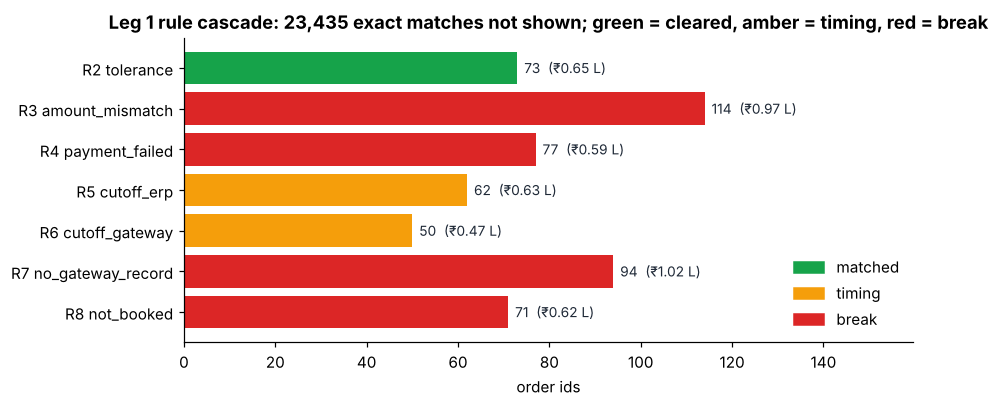

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
d = leg1[leg1.rule != "R1_exact"].iloc[::-1]
colors = {"matched": OK, "timing": AMBER, "break": WARN, "no_action": MUTED}
ax.barh(d.rule.str.replace("_", " ", n=1), d["keys"], color=[colors[o] for o in d.outcome])
for y, (k, v) in enumerate(zip(d["keys"], d.value_inr)):
    ax.text(k + 1.5, y, f"{k}  ({lakh(v)})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, d["keys"].max() * 1.4); ax.set_xlabel("order ids")
r1 = int(leg1.loc[leg1.rule.eq("R1_exact"), "keys"].iloc[0])
ax.set_title(f"Leg 1 rule cascade: {r1:,} exact matches not shown; green = cleared, amber = timing, red = break")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items() if k in set(d.outcome)], frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "05_rule_cascade.png", dpi=150, bbox_inches="tight"); plt.show()

### Could some one-sided rows be the same sale under a mistyped order id?

Before calling an ERP-only row and a gateway-only row two separate breaks, the engine looks for **probable pairs**: same amount, same payment method, within 10 minutes. `ROW_NUMBER()` picks each row's closest candidate from both directions and a pair is kept only if each is the other's best match (a mutual-best rule, which stops one gateway row being "used" twice).

In [6]:
pairs = sql("SELECT * FROM leg1_probable_pairs")
print(f"probable pairs found: {len(pairs)}")
pairs

probable pairs found: 0


,erp_order_id,gw_order_id,amount_inr,gap_min


No pairs: the one-sided rows are not hidden matches with bad keys. They're real omissions on one side, so they stay as breaks.

## 2 · Refunds, credit notes and chargebacks

In [7]:
sql("""
SELECT rule, COUNT(*) AS refunds, ROUND(SUM(refund_inr), 2) AS refund_inr,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM refund_match GROUP BY 1 ORDER BY 1
""")

,rule,refunds,refund_inr,pct
0,F1_matched,294,223956.5,68.4
1,F3_no_credit_note,133,105075.0,30.9
2,F4_next_period,3,3623.5,0.7


In [8]:
print("credit notes with no gateway refund:", sql("SELECT COUNT(*) n FROM credit_notes_without_refund").n[0])
sql("SELECT COUNT(*) AS payouts_with_chargebacks, SUM(chargeback_inr) AS chargeback_inr FROM chargebacks")

credit notes with no gateway refund: 0


,payouts_with_chargebacks,chargeback_inr
0,11,25150.0


## 3 · Fee audit with window functions

Every captured October payment is re-priced at the contracted MDR. `fee_daily` then computes each method's effective rate per IST day, and `LAG()` compares each day with the previous one. A jump of more than 10 bps is flagged as a rate change. The engine finds the wallet change **by itself**, with no date hard-coded.

In [9]:
sql("SELECT method, day_ist, ROUND(100 * rate_before, 3) AS rate_before_pct, ROUND(100 * rate_after, 3) AS rate_after_pct FROM fee_rate_changes")

,method,day_ist,rate_before_pct,rate_after_pct
0,Wallet,2026-10-15,2.0,2.25


In [10]:
sql("""
SELECT method, COUNT(*) AS txns,
       ROUND(100 * ANY_VALUE(contract_mdr), 2)                AS contract_pct,
       ROUND(100 * SUM(fee_inr) / SUM(amount_inr), 3)       AS effective_pct,
       COUNT(*) FILTER (WHERE is_overcharged)               AS txns_over,
       ROUND(SUM(excess_incl_gst_inr) FILTER (WHERE is_overcharged), 2) AS excess_incl_gst_inr
FROM fee_audit GROUP BY 1 ORDER BY txns DESC
""")

,method,txns,contract_pct,effective_pct,txns_over,excess_incl_gst_inr
0,UPI,13014,0.3,0.300,0,NaN
1,Card,5920,1.9,1.908,87,508.01
2,Wallet,2409,2.0,2.135,1308,3445.15
3,NetBanking,2350,1.5,1.500,0,NaN


## 4 · Leg 2: payouts rebuilt from their transactions (many-to-one)

One payout is hundreds of transactions. Summing the gateway's own transactions by `settlement_id` and comparing each component (gross, fee, GST, refunds) with the payout file proves the settlement arithmetic before the payout is matched to the bank.

In [11]:
lp = sql("SELECT * FROM leg2_payout_rebuild ORDER BY batch_date")
print(f"batches: {len(lp)} | tie on every component: {int(lp.ties.sum())} | partial export window: {int(lp.partial_export.sum())}")
lp.loc[~lp.ties, ["settlement_id", "gross_inr", "gross_txn", "fee_inr", "fee_txn", "partial_export"]]

batches: 32 | tie on every component: 30 | partial export window: 2


,settlement_id,gross_inr,gross_txn,fee_inr,fee_txn,partial_export
0,setl_20260930,271229.0,0.0,2929.14,0.0,True
1,setl_20261001,710768.0,647165.0,6907.83,6170.4,True


The two batches that don't tie are exactly the two whose captures fall partly before 05:30 IST on 1 Oct, outside the UTC-dated export. That's the same cut-off artefact as Day 2, now seen from the payout side. The 1 Oct batch gap is used in the cash bridge below.

## 5 · Leg 3: payout ↔ bank

In [12]:
sql("""
SELECT settlement_id, batch_date, due_date, settlement_date, net_inr, bank_date, rule, days_overdue_at_close
FROM leg3_payout_bank WHERE rule <> 'S1_matched'
""")

,settlement_id,batch_date,due_date,settlement_date,net_inr,bank_date,rule,days_overdue_at_close
0,setl_20261019,2026-10-19,2026-10-20,2026-11-03,641741.68,NaT,S4_overdue,11
1,setl_20261031,2026-10-31,2026-11-02,2026-11-02,664381.60,NaT,S3_in_transit,-2


In [13]:
sql("SELECT rule, COUNT(*) AS batches, ROUND(SUM(net_inr), 2) AS net_inr FROM leg3_payout_bank GROUP BY 1 ORDER BY 1")

,rule,batches,net_inr
0,S1_matched,30,20449800.31
1,S3_in_transit,1,664381.60
2,S4_overdue,1,641741.68


## 6 · The exception register

One table across all three legs. Each row is one item a person has to work, with an owner, an action, its age at month end, its rank within its type and its cumulative share of total break value. Fee overcharges are rolled up into one claim per method; the per-transaction evidence stays in `fee_audit`.

In [14]:
summary = sql("SELECT * FROM exception_summary")
summary

,class,exception_type,owner,items,txns,impact_inr,oldest_days
0,break,SETTLEMENT_OVERDUE,Treasury,1,1.0,641741.68,11
1,break,REFUND_NO_CREDIT_NOTE,Finance (AR),133,133.0,105075.00,27
2,break,NO_GATEWAY_RECORD,Finance (AR),94,94.0,102268.00,30
3,break,GATEWAY_NOT_BOOKED,Finance (GL),71,71.0,61929.00,30
4,break,BOOKED_PAYMENT_FAILED,Finance (AR),77,77.0,58982.00,30
5,break,CHARGEBACK_NOT_BOOKED,Finance (AR),11,11.0,25150.00,27
6,break,AMOUNT_MISMATCH,E-commerce ops,114,114.0,11553.00,30
7,claim,FEE_ABOVE_CONTRACT,Treasury / vendor manager,2,1395.0,3953.16,29
8,timing,SETTLEMENT_IN_TRANSIT,Treasury,1,1.0,664381.60,-2
9,timing,CUTOFF_TIMING,Finance (GL),115,115.0,113626.50,30


In [15]:
reg = sql("SELECT * FROM exception_register ORDER BY exception_id")
brk = reg[reg["class"] == "break"]
print(f"register items: {len(reg)} | breaks: {len(brk)} worth {lakh(brk.impact_inr.sum())} | "
      f"claims: {(reg['class'] == 'claim').sum()} | timing: {(reg['class'] == 'timing').sum()}")
n80 = int((brk.cum_share_of_breaks < 0.8).sum()) + 1
print(f"items covering 80% of break value: {n80} of {len(brk)}")
print(f"largest single break: {brk.iloc[0].exception_type} {brk.iloc[0].ref} = {lakh(brk.iloc[0].impact_inr)} "
      f"({brk.iloc[0].cum_share_of_breaks:.1%} of break value)")

register items: 619 | breaks: 501 worth ₹10.07 L | claims: 2 | timing: 116
items covering 80% of break value: 72 of 501
largest single break: SETTLEMENT_OVERDUE setl_20261019 = ₹6.42 L (63.7% of break value)


**A work queue per owner.** `QUALIFY` filters on a window function without a sub-query. Here it's the top three breaks for each owner, which is the list each person would start their day with.

In [16]:
sql("""
SELECT owner, exception_type, ref, ROUND(impact_inr, 2) AS impact_inr, age_days
FROM exception_register
WHERE class = 'break'
QUALIFY ROW_NUMBER() OVER (PARTITION BY owner ORDER BY ABS(impact_inr) DESC) <= 3
ORDER BY owner, impact_inr DESC
""")

,owner,exception_type,ref,impact_inr,age_days
0,E-commerce ops,AMOUNT_MISMATCH,ORD-1003355,732.00,27
1,E-commerce ops,AMOUNT_MISMATCH,ORD-1009899,343.00,18
2,E-commerce ops,AMOUNT_MISMATCH,ORD-1003157,336.00,27
3,Finance (AR),NO_GATEWAY_RECORD,ORD-1013302,6568.00,14
4,Finance (AR),NO_GATEWAY_RECORD,ORD-1010831,6143.00,17
5,Finance (AR),CHARGEBACK_NOT_BOOKED,setl_20261019,5470.00,12
6,Finance (GL),GATEWAY_NOT_BOOKED,ORD-1015217,3835.00,11
7,Finance (GL),GATEWAY_NOT_BOOKED,ORD-1009455,2515.00,19
8,Finance (GL),GATEWAY_NOT_BOOKED,ORD-1022625,1914.00,2
9,Treasury,SETTLEMENT_OVERDUE,setl_20261019,641741.68,11


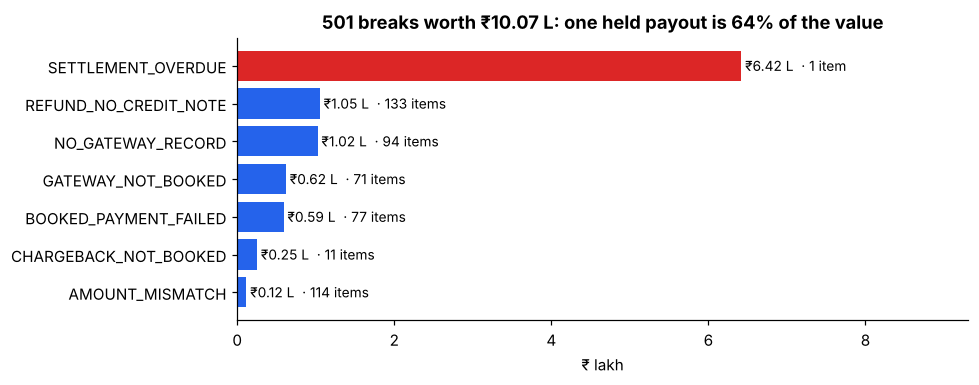

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
s = summary[summary["class"] == "break"].sort_values("impact_inr")
ax.barh(s.exception_type, s.impact_inr / 1e5, color=[WARN if t == "SETTLEMENT_OVERDUE" else ACCENT for t in s.exception_type])
for y, (v, n) in enumerate(zip(s.impact_inr, s["items"])):
    ax.text(v / 1e5 + 0.05, y, f"{lakh(v)}  · {n} item{'s' if n > 1 else ''}", va="center", fontsize=9)
ax.set_xlim(0, s.impact_inr.max() / 1e5 * 1.45); ax.set_xlabel("₹ lakh")
ax.set_title(f"{len(brk)} breaks worth {lakh(brk.impact_inr.sum())}: one held payout is {brk.iloc[0].cum_share_of_breaks:.0%} of the value")
plt.tight_layout(); plt.savefig(IMG / "06_exception_register.png", dpi=150, bbox_inches="tight"); plt.show()

## 7 · Cash bridge: from ERP net sales to the bank

Day 2 left a ₹15.41 L gap between October ERP net sales and PayFlux credits in the bank. `60_cash_bridge.sql` explains it step by step from the match tables, with a running total, and puts whatever is left in an **Unexplained** line. The engine's integrity checks fail if that line is more than ₹1.

In [18]:
bridge = sql("SELECT * FROM cash_bridge ORDER BY step")
bridge

,step,item,kind,amount_inr,running_inr
0,1,"ERP net sales, October (receipts + credit notes)",start,21991231.50,21991231.50
1,2,Booked but never captured (no record / failed),break,-161250.00,21829981.50
2,3,Captured but never booked,break,61929.00,21891910.50
3,4,Checkout discounts not passed to ERP (amount mismatch),break,-11553.00,21880357.50
4,5,Rounding within ±₹1,matched,-1.00,21880356.50
5,6,Cut-off: unexported 1 Oct captures not in ERP,timing,256.00,21880612.50
6,7,Gateway fees (MDR) and 18% GST on fees,cost,-262236.51,21618375.99
7,8,Refunds netted by gateway with no ERP credit note,break,-105075.00,21513300.99
8,9,Credit-note vs refund differences and refund timing,timing,0.00,21513300.99
9,10,"Chargebacks netted from payouts, not booked",break,-25150.00,21488150.99


In [19]:
start = bridge.amount_inr.iloc[0]; end = bridge.amount_inr.iloc[-1]
resid = bridge.loc[bridge.kind == "residual", "amount_inr"].iloc[0]
print(f"gap to explain: {lakh(start - end)} (₹{start - end:,.2f}) | unexplained after bridge: ₹{resid:,.2f}")

gap to explain: ₹15.41 L (₹1,541,431.19) | unexplained after bridge: ₹0.00


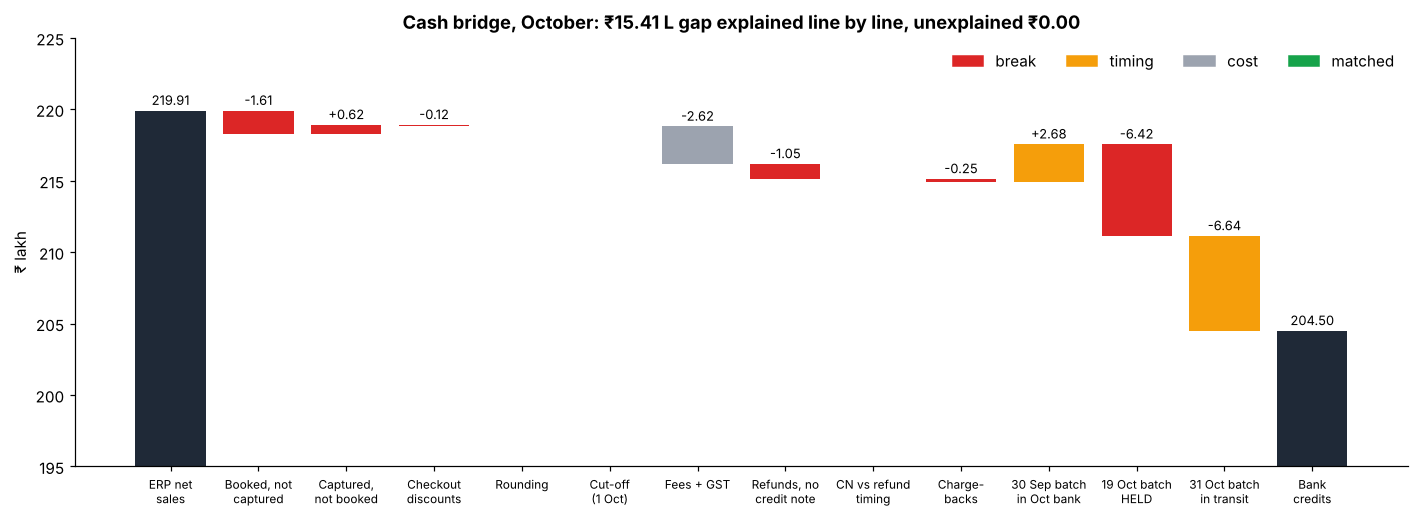

In [20]:
fig, ax = plt.subplots(figsize=(13, 4.8))
steps = bridge[~bridge.kind.isin(["start", "end", "residual"])]
short = {2: "Booked, not\ncaptured", 3: "Captured,\nnot booked", 4: "Checkout\ndiscounts", 5: "Rounding",
         6: "Cut-off\n(1 Oct)", 7: "Fees + GST", 8: "Refunds, no\ncredit note", 9: "CN vs refund\ntiming",
         10: "Charge-\nbacks", 11: "30 Sep batch\nin Oct bank", 12: "19 Oct batch\nHELD", 13: "31 Oct batch\nin transit"}
col = {"break": WARN, "timing": AMBER, "cost": MUTED, "matched": OK}
ax.bar(0, start / 1e5, color=INK); ax.text(0, start / 1e5 + 0.4, f"{start/1e5:,.2f}", ha="center", fontsize=8.5)
prev = start
for i, r in enumerate(steps.itertuples(), start=1):
    lo, hi = sorted([prev, prev + r.amount_inr])
    ax.bar(i, max((hi - lo) / 1e5, 0.02), bottom=lo / 1e5, color=col[r.kind])
    if abs(r.amount_inr) >= 1000:
        ax.text(i, hi / 1e5 + 0.4, f"{r.amount_inr/1e5:+.2f}", ha="center", fontsize=8.5)
    prev += r.amount_inr
n = len(steps) + 1
ax.bar(n, end / 1e5, color=INK); ax.text(n, end / 1e5 + 0.4, f"{end/1e5:,.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(n + 1), ["ERP net\nsales"] + [short[s] for s in steps.step] + ["Bank\ncredits"], fontsize=7.8)
ax.set_ylim(195, 225); ax.set_ylabel("₹ lakh")
ax.set_title(f"Cash bridge, October: {lakh(start - end)} gap explained line by line, unexplained ₹{resid:,.2f}")
ax.legend(handles=[Patch(color=c, label=k) for k, c in col.items()], frameon=False, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(IMG / "07_cash_bridge.png", dpi=150, bbox_inches="tight"); plt.show()

## Summary

- The SQL cascade auto-clears more keys than Day 2's exact join because the ±₹1 rule removes rounding noise, and it moves the cut-off rows into **timing** instead of breaks.
- The probable-pair search found no mistyped keys, so one-sided rows are real omissions.
- `LAG()` over daily effective rates finds the wallet MDR change date without it being hard-coded.
- Payouts rebuild exactly from their transactions for every batch fully inside the export window.
- The exception register turns ~24k rows into a few hundred owned items; the held 19 Oct payout alone is most of the break value.
- The cash bridge explains the whole ERP-to-bank gap with **zero unexplained**.

Exact figures are printed in the cells above and repeated in the README.

**Next (Day 4):** score the engine against `data/truth/labels.csv`: precision and recall per exception type, and a look at every miss.